In [1]:
# General notebook settings
import logging
import warnings

import pypsa

warnings.filterwarnings("error", category=DeprecationWarning)
# pandas<3.0.3 sets the `locs` attribute deprecated in matplotlib>=3.11
warnings.filterwarnings("ignore", message="The locs attribute was deprecated")
logging.getLogger("gurobipy").propagate = False
pypsa.options.params.optimize.log_to_console = False

# Meshed AC-DC Networks

This example demonstrates how to optimise meshed AC-DC networks in PyPSA. The example has a 3-node AC network coupled via AC-DC converters to a 3-node DC network. There is also a single point-to-point DC connection using the `Link` component.

In [2]:
import pypsa

n = pypsa.examples.ac_dc_meshed()
n.links.loc["Norwich Converter", "p_nom_extendable"] = False

/home/runner/work/PyPSA/PyPSA/pypsa/network/io.py:2079: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)


INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads


{'nodes': {'Bus': <matplotlib.collections.PatchCollection at 0x7f73cf7ec050>},
 'branches': {'Link': <matplotlib.collections.LineCollection at 0x7f73cf7ec1a0>,
  'Line': <matplotlib.collections.LineCollection at 0x7f73d405fd90>},
 'flows': {}}

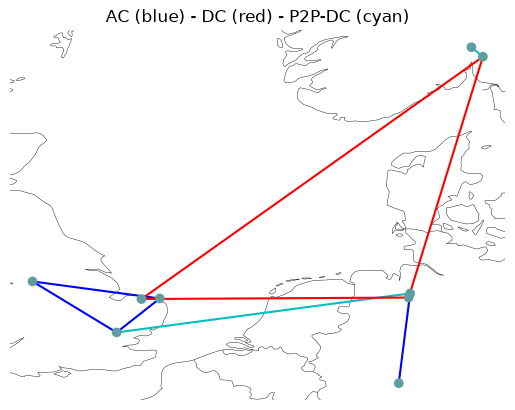

In [3]:
line_color = n.lines.bus0.map(n.buses.carrier).map(
    lambda ct: "r" if ct == "DC" else "b"
)

n.plot(
    line_color=line_color,
    link_color="c",
    title="AC (blue) - DC (red) - P2P-DC (cyan)",
    jitter=0.4,
)

We inspect the topology of the network. Therefore, use `n.determine_network_topology()` and inspect the subnetworks in `n.sub_networks`.

In [4]:
n.determine_network_topology()
n.sub_networks["n_branches"] = [len(sn.branches()) for sn in n.sub_networks.obj]
n.sub_networks["n_buses"] = [
    len(sn.components.buses.static) for sn in n.sub_networks.obj
]

n.sub_networks

,carrier,slack_bus,obj,n_branches,n_buses
name,,,,,
0,AC,Manchester,<pypsa.networks.SubNetwork object at 0x7f73cf7...,3,3
1,DC,Norwich DC,<pypsa.networks.SubNetwork object at 0x7f73d47...,3,3
2,AC,Frankfurt,<pypsa.networks.SubNetwork object at 0x7f73cf7...,1,2
3,AC,Norway,<pypsa.networks.SubNetwork object at 0x7f73cf7...,0,1


The network covers 10 time steps. These are given by the `snapshots` attribute.

In [5]:
n.snapshots

DatetimeIndex(['2015-01-01 00:00:00', '2015-01-01 01:00:00',
               '2015-01-01 02:00:00', '2015-01-01 03:00:00',
               '2015-01-01 04:00:00', '2015-01-01 05:00:00',
               '2015-01-01 06:00:00', '2015-01-01 07:00:00',
               '2015-01-01 08:00:00', '2015-01-01 09:00:00'],
              dtype='datetime64[ns]', name='snapshot', freq=None)

There are 6 generators in the network, 3 wind and 3 gas. All are attached to AC buses:

In [6]:
n.generators

,bus,control,type,p_nom,p_nom_mod,p_nom_extendable,p_nom_min,p_nom_max,p_nom_set,p_min_pu,...,min_down_time,up_time_before,down_time_before,ramp_limit_up,ramp_limit_down,ramp_limit_start_up,ramp_limit_shut_down,weight,p_nom_opt,capital_cost_piecewise_opt
name,,,,,,,,,,,,,,,,,,,,,
Manchester Wind,Manchester,Slack,,80.0,0.0,True,100.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Manchester Gas,Manchester,PQ,,50000.0,0.0,True,0.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Norway Wind,Norway,Slack,,100.0,0.0,True,100.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Norway Gas,Norway,PQ,,20000.0,0.0,True,0.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Frankfurt Wind,Frankfurt,Slack,,110.0,0.0,True,100.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0
Frankfurt Gas,Frankfurt,PQ,,80000.0,0.0,True,0.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,0.0,0.0


We see that the generators have different capital and marginal costs. All of them have a `p_nom_extendable` set to `True`, meaning that capacities can be extended in the optimisation. The wind generators have a per unit limit for each time step, given by the weather potentials at the site. 

<Axes: xlabel='snapshot'>

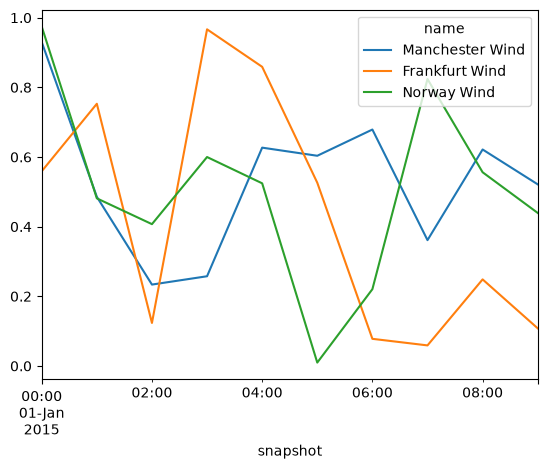

In [7]:
n.generators_t.p_max_pu.plot()

Alright now we know how the network looks like, where the generators and lines are. Now, let's perform a optimization of the operation and capacities.

In [8]:
n.optimize();

/tmp/ipykernel_2523/1450685117.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize();
Index(['2', '3', '4'], dtype='object', name='name')


Index(['0', '1', '5', '6'], dtype='object', name='name')


INFO:linopy.model: Solve problem using Gurobi solver


INFO:linopy.model:Solver options:
 - log_to_console: False


INFO:linopy.io: Writing time: 0.07s


...

Reading time = 0.00 seconds


obj: 467 rows, 187 columns, 986 nonzeros


Set parameter LogToConsole to value 0


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -3.47e+06
Solver: gurobi
Runtime: 0.00s
Dual bound: -3.47e+06
Solver model: available
Solver message: 2



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-lower, Link-fix-p-upper, Link-ext-p-lower, Link-ext-p-upper, Kirchhoff-Voltage-Law were not assigned to the network.


The objective is given by:

In [9]:
n.objective

-3474094.1308162357

Why is this number negative? It considers the starting point of the optimisation, thus the existent capacities given by `n.generators.p_nom` are taken into account.  

The real system cost are given by

In [10]:
n.objective + n.objective_constant

18440973.387462907

The optimal capacities are given by `p_nom_opt` for generators, links and storages and `s_nom_opt` for lines.

Let's look how the optimal capacities for the generators look like.

In [11]:
n.generators.p_nom_opt.div(1e3).round(2).sort_values()

name
Manchester Gas     0.00
Norway Gas         0.00
Frankfurt Gas      0.98
Norway Wind        1.53
Frankfurt Wind     1.67
Manchester Wind    4.09
Name: p_nom_opt, dtype: float64

Their production is again given as a time-series in `n.generators_t`.

<Axes: xlabel='snapshot', ylabel='GW'>

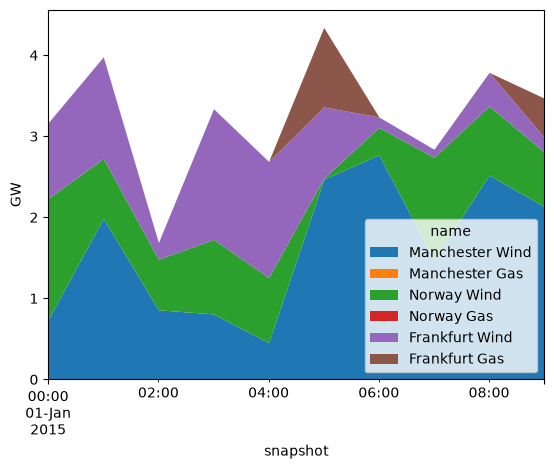

In [12]:
n.generators_t.p.div(1e3).plot.area(stacked=True, lw=0, ylabel="GW")

What are the locational marginal prices in the network? From the optimisation these are given for each bus and snapshot.

<Axes: xlabel='snapshot', ylabel='€/MWh'>

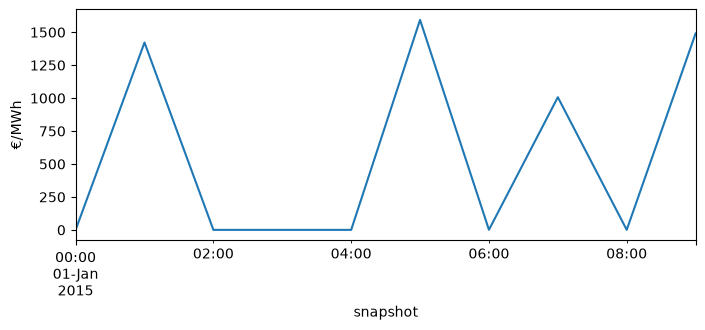

In [13]:
n.buses_t.marginal_price.mean(axis=1).plot(figsize=(8, 3), ylabel="€/MWh")

We can inspect further quantities as the active power of AC-DC converters and HVDC link.

In [14]:
n.links_t.p0.round(2)

name,Norwich Converter,Norway Converter,Bremen Converter,DC link
snapshot,,,,
2015-01-01 00:00:00,-475.91,674.58,-198.67,-92.93
2015-01-01 01:00:00,315.07,-116.73,-198.34,-318.00
2015-01-01 02:00:00,350.76,581.97,-932.73,-318.00
2015-01-01 03:00:00,-721.77,272.56,449.21,318.00
2015-01-01 04:00:00,317.37,-79.75,-237.62,-318.00
2015-01-01 05:00:00,-62.83,-494.20,557.03,131.58
2015-01-01 06:00:00,900.00,-257.52,-642.48,318.00
2015-01-01 07:00:00,123.68,971.92,-1095.60,-86.86
2015-01-01 08:00:00,244.72,850.88,-1095.60,318.00


In [15]:
n.lines_t.p0.round(2)

name,0,1,2,3,4,5,6
snapshot,,,,,,,
2015-01-01 00:00:00,41.82,-75.76,129.66,-346.25,328.34,-15.31,-534.34
2015-01-01 01:00:00,-449.46,787.04,-211.27,103.80,-12.93,209.36,-823.21
2015-01-01 02:00:00,-181.27,520.56,-505.91,-155.15,426.82,-248.68,173.90
2015-01-01 03:00:00,-151.89,128.06,482.03,-239.74,32.82,296.87,-743.79
2015-01-01 04:00:00,-73.21,295.42,-227.20,90.17,10.42,-240.11,-883.82
2015-01-01 05:00:00,-669.72,1122.86,238.90,176.07,-318.13,393.72,-1030.85
2015-01-01 06:00:00,-661.29,1378.42,-632.37,267.63,10.11,-53.45,319.39
2015-01-01 07:00:00,-383.77,540.91,-469.93,-346.25,625.67,393.72,600.73
2015-01-01 08:00:00,-778.28,1444.07,-522.12,-277.40,573.48,229.29,501.35


...or the active power injection per bus.

In [16]:
n.buses_t.p.round(2)

name,London,Norwich,Norwich DC,Manchester,Bremen,Bremen DC,Frankfurt,Norway,Norway DC
snapshot,,,,,,,,,
2015-01-01 00:00:00,57.13,60.45,-475.91,-117.58,-534.34,-198.67,534.34,0.0,674.58
2015-01-01 01:00:00,-658.83,-577.67,315.07,1236.50,-823.21,-198.34,823.21,0.0,-116.73
2015-01-01 02:00:00,67.41,-769.24,350.76,701.83,173.90,-932.73,-173.90,0.0,581.97
2015-01-01 03:00:00,-448.75,168.81,-721.77,279.94,-743.79,449.21,743.79,0.0,272.56
2015-01-01 04:00:00,166.90,-535.53,317.37,368.63,-883.82,-237.62,883.82,0.0,-79.75
2015-01-01 05:00:00,-1063.44,-729.15,-62.83,1792.58,-1030.85,557.03,1030.85,0.0,-494.20
2015-01-01 06:00:00,-607.85,-1431.87,900.00,2039.72,319.39,-642.48,-319.39,0.0,-257.52
2015-01-01 07:00:00,-777.48,-147.19,123.68,924.68,600.73,-1095.60,-600.73,0.0,971.92
2015-01-01 08:00:00,-1007.58,-1214.77,244.72,2222.35,501.35,-1095.60,-501.35,0.0,850.88
